# Tiamat: comparação de modelos para prever tipos de feijão seco

## Introdução

## Criando o DataFrame

In [2]:
import pandas as pd

feijoes = 'Dry_Bean_Dataset.xlsx'
df_feijoes = pd.read_excel(feijoes)
df_feijoes

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON


## Análise exploratória dos dados

In [3]:
df_feijoes.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [5]:
df_feijoes['Class'].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

### Matriz de correlação

O método `DataFrame.corr()` do Pandas é usado para calcular a correlação entre colunas numéricas em um DataFrame. A correlação mostra a intensidade da relação entre duas colunas. O resultado é retornado como um novo DataFrame chamado matriz de correlação, onde cada valor varia de -1 a 1 [1].
- **1**: correlação positiva perfeita
- **-1**: correlação negativa perfeita
- **0**: nenhuma correlação

In [7]:
ma_correlacao = df_feijoes.corr(numeric_only=True)
ma_correlacao

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.000000,0.966722,0.931834,0.951602,0.241735,0.267481,0.999939,0.984968,0.054345,-0.196585,-0.357530,-0.268067,-0.847958,-0.639291,-0.272145,-0.355721
Perimeter,0.966722,1.000000,0.977338,0.913179,0.385276,0.391066,0.967689,0.991380,-0.021160,-0.303970,-0.547647,-0.406857,-0.864623,-0.767592,-0.408435,-0.429310
MajorAxisLength,0.931834,0.977338,1.000000,0.826052,0.550335,0.541972,0.932607,0.961733,-0.078062,-0.284302,-0.596358,-0.568377,-0.773609,-0.859238,-0.568185,-0.482527
MinorAxisLength,0.951602,0.913179,0.826052,1.000000,-0.009161,0.019574,0.951339,0.948539,0.145957,-0.155831,-0.210344,-0.015066,-0.947204,-0.471347,-0.019326,-0.263749
AspectRation,0.241735,0.385276,0.550335,-0.009161,1.000000,0.924293,0.243301,0.303647,-0.370184,-0.267754,-0.766979,-0.987687,0.024593,-0.837841,-0.978592,-0.449264
Eccentricity,0.267481,0.391066,0.541972,0.019574,0.924293,1.000000,0.269255,0.318667,-0.319362,-0.297592,-0.722272,-0.970313,0.019920,-0.860141,-0.981058,-0.449354
ConvexArea,0.999939,0.967689,0.932607,0.951339,0.243301,0.269255,1.000000,0.985226,0.052564,-0.206191,-0.362083,-0.269922,-0.847950,-0.640862,-0.274024,-0.362049
EquivDiameter,0.984968,0.991380,0.961733,0.948539,0.303647,0.318667,0.985226,1.000000,0.028383,-0.231648,-0.435945,-0.327650,-0.892741,-0.713069,-0.330389,-0.392512
Extent,0.054345,-0.021160,-0.078062,0.145957,-0.370184,-0.319362,0.052564,0.028383,1.000000,0.191389,0.344411,0.354212,-0.141616,0.237956,0.347624,0.148502
Solidity,-0.196585,-0.303970,-0.284302,-0.155831,-0.267754,-0.297592,-0.206191,-0.231648,0.191389,1.000000,0.607150,0.303766,0.153388,0.343559,0.307662,0.702163


Há maneiras mais fáceis de interpretar esse resultado e por isso, muitas vezes, a matriz de correlação é representada visualmente. Veja na célula abaixo o código modificado que gera esta representação visual. [3]

Text(0.5, 1.0, 'Representação visual da matriz de correlação')

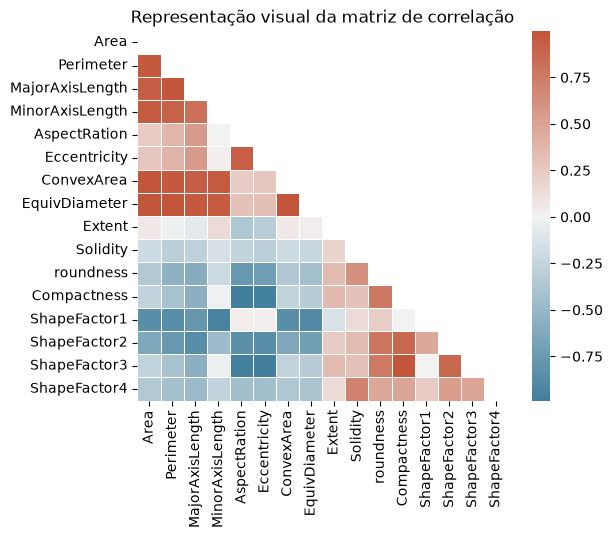

In [18]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

mascara = np.triu(np.ones_like(ma_correlacao, dtype=bool))
mapa_de_cor = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    ma_correlacao,
    mask=mascara,
    cmap=mapa_de_cor,
    center=0,
    square=True,
    linewidths=0.5,
);

plt.title('Representação visual da matriz de correlação')

### Histograma da área

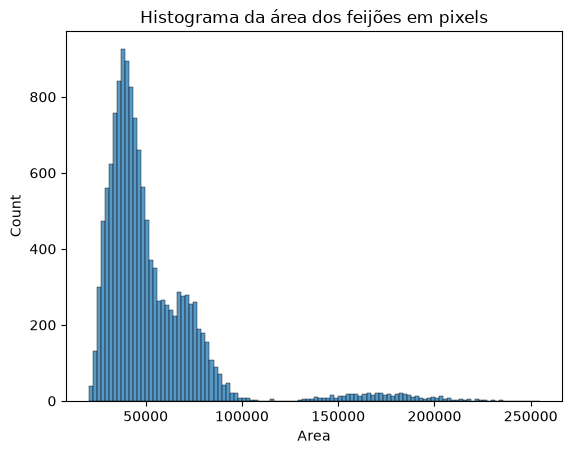

In [19]:
sns.histplot(data = df_feijoes['Area'].to_frame(), x='Area')
plt.title('Histograma da área dos feijões em pixels')
plt.show()

### Boxplot por classe

A partir da intepretação do gráfico da matriz de corelação, escolhemos os atributos mais intuitivos: Area, Perimeter, MajorAxisLength, MinorAxisLength, Compactness e Roundness

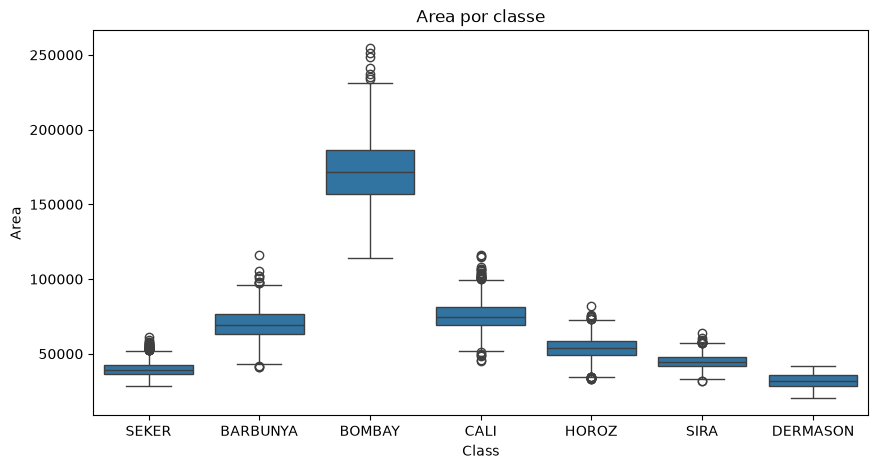

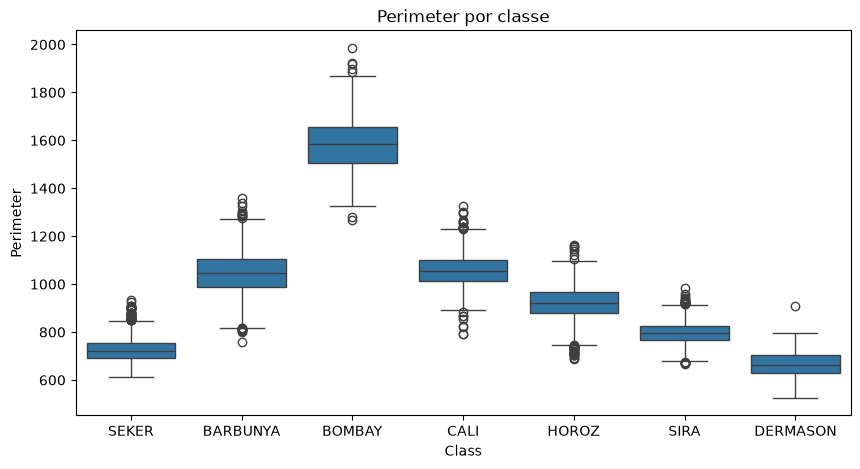

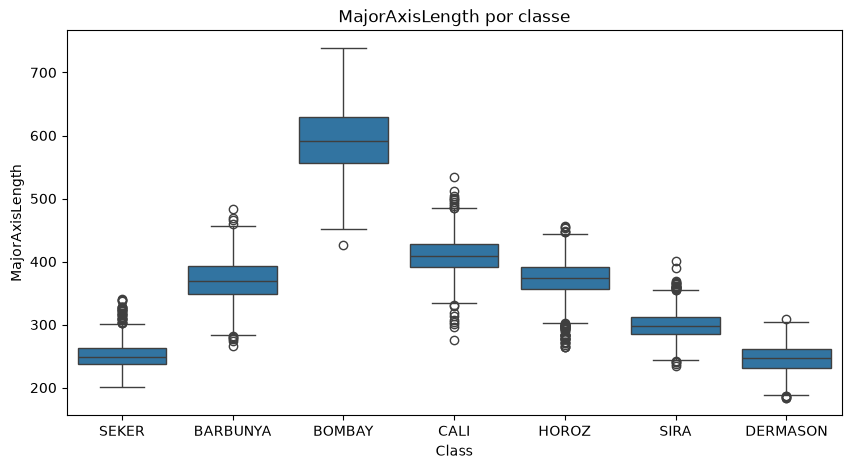

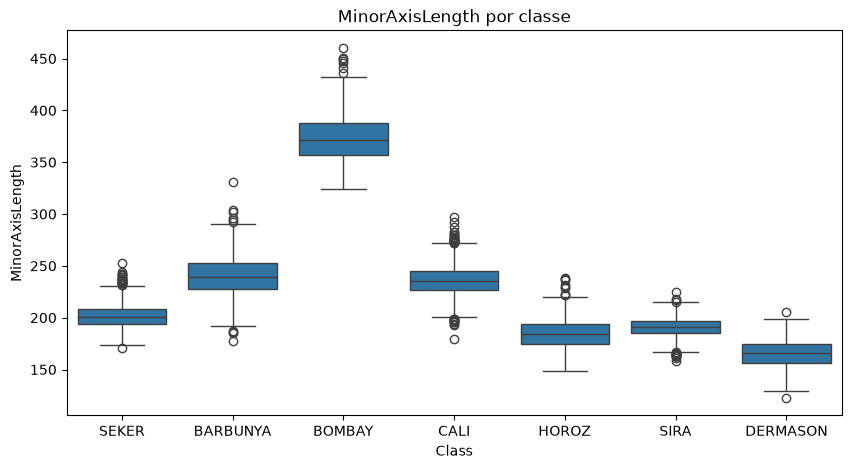

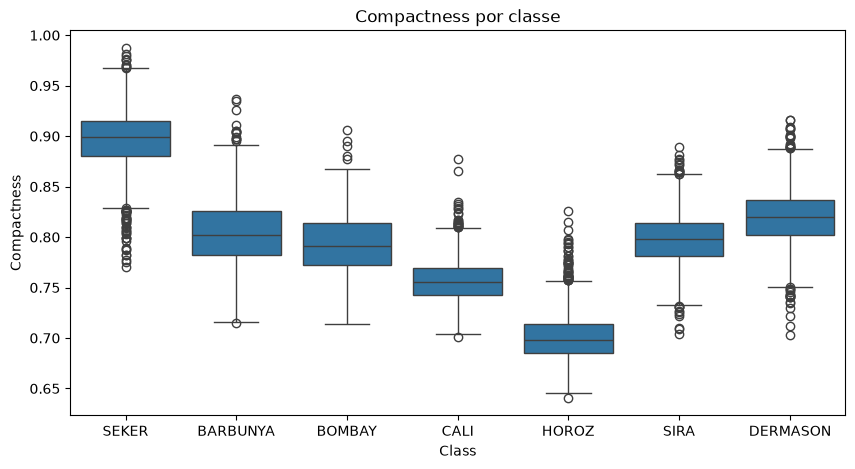

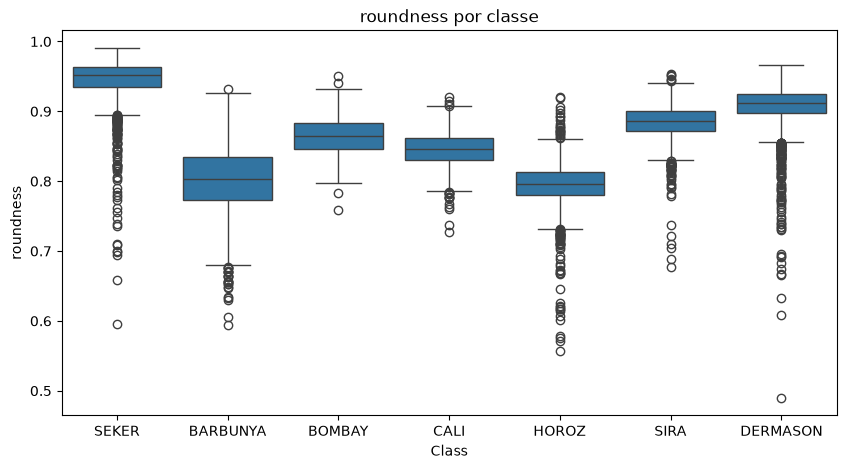

In [21]:
atributos = [
    'Area',
    'Perimeter',
    'MajorAxisLength',
    'MinorAxisLength',
    'Compactness',
    'roundness'
]

for atributo in atributos:
    plt.figure(figsize=(10,5))
    
    sns.boxplot(
        data=df_feijoes,
        x='Class',
        y=atributo
    )

    plt.title(f'{atributo} por classe')
    plt.show()

## Modelo Baseline

## Divisão em treino e teste

## Normalização dos dados

## Modelo k-NN

## Árvore de Decisão

## Floresta Aleatória

## Conclusões e principais aprendizados

## Descrição de uso de IA neste trabalho

## Referências

1 - **Repositório do Dataset "Dry Bean"**: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset

2 - **Tutorial do método corr() do Pandas**: https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-corr/

3 - **Notebook ATP-203 8.0 - Redução de dimensionalidade com PCA**: fornecido pelo professor

4 - **Tutorial de histograma utilizando o módulo `seaborn`**: https://hub.asimov.academy/tutorial/como-customizar-um-histograma-com-python-e-seaborn/